In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
# 1. Load data correctly, bypassing unclosed quotes with line-by-line parsing fallback
import pandas as pd
import csv

try:
    # Read file using a csv reader that handles mismatched quotes by disabling quote parsing if it fails
    data = []
    with open("indonesia_mbg_nationwide_enriched_2026.csv", "r", encoding="utf-8", errors="ignore") as f:
        reader = csv.reader(f)
        header = next(reader)
        for row in reader:
            # Ensure row length matches header length to prevent shifted columns
            if len(row) == len(header):
                data.append(row)
            else:
                # If unclosed quote causes line splitting issues, append only valid parts or clean line
                data.append(row[:len(header)] + [None] * (len(header) - len(row)))

    df = pd.DataFrame(data, columns=header)
    print("Successfully loaded dataset! Shape:", df.shape)
except Exception as e:
    print("Standard CSV parsing failed, using fallback:", e)
    # Ultimate fallback: split purely by comma ignoring all quotes entirely
    df = pd.read_csv("indonesia_mbg_nationwide_enriched_2026.csv", quoting=csv.QUOTE_NONE, on_bad_lines='skip')

Successfully loaded dataset! Shape: (9690, 26)


In [ ]:
df.head()

,,,,,,,,,distribution_id,province,regional_cluster,beneficiary_category,kitchen_daily_capacity_portions,raw_ingredient_cost_per_portion_idr,protein_type,delivery_distance_km,delivery_transport_mode,transit_time_minutes,...,estimated_protein_grams,transit_cooling_rate_c_per_min,spoilage_risk_index,cost_to_nutrition_ratio,local_economic_multiplier_score,waste_adjusted_effective_cost_idr,bgn_program_compliance_tier,primary_food_waste_driver,cot_nutrition_logistics_rationale,confidence_score
ID_MBG_032C662783,Aceh,Daerah Pedesaan & Kepulauan,Balita & Ibu Hamil Posyandu,1422,14500,Daging Sapi / Kerbau,24.5,Mobil Pickup Termal,77,56.9,16.3,91.9,73.9,15000.0,665.0,29.1,0.235,4.57,...,kapasitas dapur SPPG: 1,422 porsi/hari) menggunakan protein 'Daging Sa...,500 dan total biaya per porsi Rp15,000. Pengiriman sejauh 24.5 km menggunakan mod...,serapan petani lokal 73.9% (skor dampak ekono...,dan sisa makanan 16.3% (biaya efektif disesua...,921/porsi),evaluasi mengklasifikasikan operasional ke da...,dengan pemicu utama sisa makanan teridentifik...,0.981
ID_MBG_22CCF7D0D8,Aceh,Daerah Pedesaan & Kepulauan,Siswa SD / Madrasah Ibtidaiyah,1120,11300,Daging Ayam Broiler,3.0,Mobil Pickup Termal,11,67.0,20.4,93.7,81.0,13535.0,596.0,22.7,0.727,0.70,...,kapasitas dapur SPPG: 1,120 porsi/hari) menggunakan protein 'Daging Ay...,300 dan total biaya per porsi Rp13,535. Pengiriman sejauh 3.0 km menggunakan moda...,serapan petani lokal 81.0% (skor dampak ekono...,dan sisa makanan 20.4% (biaya efektif disesua...,004/porsi),evaluasi mengklasifikasikan operasional ke da...,dengan pemicu utama sisa makanan teridentifik...,0.948
ID_MBG_6BCE8CF6D2,Aceh,Daerah Pedesaan & Kepulauan,Siswa SD / Madrasah Ibtidaiyah,1211,11500,Ikan Kembung / Lele / Bandeng,10.3,Mobil Pickup Termal,34,61.6,22.5,95.0,86.7,14064.0,590.0,21.3,0.394,1.75,...,kapasitas dapur SPPG: 1,211 porsi/hari) menggunakan protein 'Ikan Kemb...,500 dan total biaya per porsi Rp14,064. Pengiriman sejauh 10.3 km menggunakan mod...,serapan petani lokal 86.7% (skor dampak ekono...,dan sisa makanan 22.5% (biaya efektif disesua...,147/porsi),evaluasi mengklasifikasikan operasional ke da...,dengan pemicu utama sisa makanan teridentifik...,0.965
ID_MBG_8318DDB506,Aceh,Daerah Pedesaan & Kepulauan,Santri Pondok Pesantren,1391,9200,Telur Ayam Boiler,5.6,Perahu Ketinting Sungai / Laut,36,54.6,10.2,88.8,70.0,11752.0,734.0,19.9,0.567,5.35,...,kapasitas dapur SPPG: 1,391 porsi/hari) menggunakan protein 'Telur Aya...,200 dan total biaya per porsi Rp11,752. Pengiriman sejauh 5.6 km menggunakan moda...,serapan petani lokal 70.0% (skor dampak ekono...,dan sisa makanan 10.2% (biaya efektif disesua...,087/porsi),evaluasi mengklasifikasikan operasional ke da...,dengan pemicu utama sisa makanan teridentifik...,0.975
ID_MBG_8502DFD13B,Aceh,Daerah Pedesaan & Kepulauan,Siswa SD / Madrasah Ibtidaiyah,768,14500,Daging Sapi / Kerbau,10.4,Mobil Pickup Termal,36,63.8,10.3,90.5,67.9,15000.0,675.0,28.1,0.311,1.84,...,kapasitas dapur SPPG: 768 porsi/hari) menggun...,500 dan total biaya per porsi Rp15,000. Pengiriman sejauh 10.4 km menggunakan mod...,serapan petani lokal 67.9% (skor dampak ekono...,dan sisa makanan 10.3% (biaya efektif disesua...,722/porsi),evaluasi mengklasifikasikan operasional ke da...,dengan pemicu utama sisa makanan teridentifik...,0.959,NaN


In [ ]:
# 2. Ringkasan Agregasi Data Utama dengan Data yang Sudah Bersih

# Pastikan kolom-kolom dikonversi ke tipe data numerik yang tepat
numeric_cols = [
    'raw_ingredient_cost_per_portion_idr',
    'estimated_protein_grams',
    'cost_to_nutrition_ratio',
    'plate_waste_percentage',
    'spoilage_risk_index',
    'local_farmer_sourcing_pct',
    'transit_time_minutes'
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# a. Efisiensi Biaya per Gram Protein berdasarkan Jenis Protein
protein_summary = df.groupby('protein_type').agg(
    biaya_bahan_baku=('raw_ingredient_cost_per_portion_idr', 'mean'),
    estimasi_protein_g=('estimated_protein_grams', 'mean'),
    rasio_biaya_per_g_protein=('cost_to_nutrition_ratio', 'mean')
).reset_index().sort_values(by='rasio_biaya_per_g_protein')

# b. Analisis Kinerja Operasional per Klaster Wilayah
cluster_summary = df.groupby('regional_cluster').agg(
    sisa_makanan_pct=('plate_waste_percentage', 'mean'),
    indeks_risiko_pembusukan=('spoilage_risk_index', 'mean'),
    serapan_petani_lokal_pct=('local_farmer_sourcing_pct', 'mean'),
    waktu_transit_menit=('transit_time_minutes', 'mean')
).reset_index()

print("--- Efisiensi Jenis Protein ---")
print(protein_summary.to_string(index=False))
print("\n--- Analisis Klaster Wilayah ---")
print(cluster_summary.to_string(index=False))

--- Efisiensi Jenis Protein ---
                 protein_type  biaya_bahan_baku  estimasi_protein_g  rasio_biaya_per_g_protein
         Daging Sapi / Kerbau      14155.420054           30.250000                 498.835772
          Daging Ayam Broiler      11796.484032           25.452710                 556.544946
Ikan Kembung / Lele / Bandeng      11077.603424           23.378412                 579.046410
            Telur Ayam Boiler       9769.927536           17.648623                 698.174203
      Susu Pasteurisasi Segar      12589.349112           18.351923                 809.403698

--- Analisis Klaster Wilayah ---
                 regional_cluster  sisa_makanan_pct  indeks_risiko_pembusukan  serapan_petani_lokal_pct  waktu_transit_menit
      Daerah Pedesaan & Kepulauan         14.110930                  3.306426                 82.526924            31.832046
                Jawa Metropolitan         13.382386                  1.562268                 57.499944           

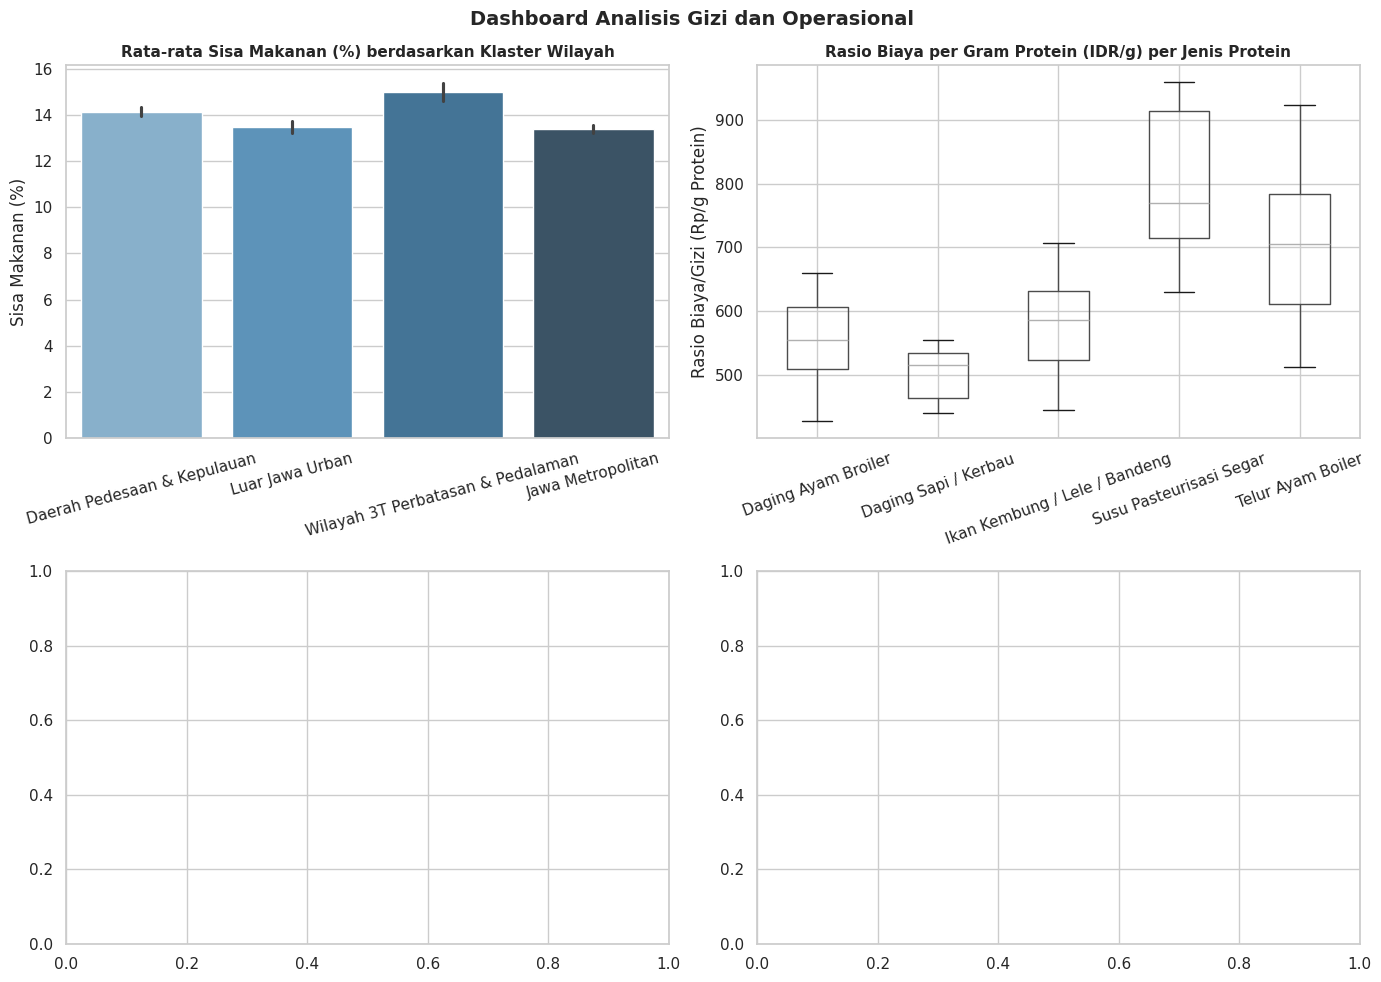

/tmp/ipykernel_3554/1706788623.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='primary_food_waste_driver', order=df['primary_food_waste_driver'].value_counts().index, ax=axes[1, 1], palette='mako')


<Figure size 640x480 with 0 Axes>

In [ ]:
# 3. Visualisasi Multi-Panel (Dashboard EDA)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Rata-rata Sisa Makanan per Klaster Wilayah
sns.barplot(data=df, x='regional_cluster', y='plate_waste_percentage', ax=axes[0, 0], hue='regional_cluster', palette='Blues_d', legend=False)
axes[0, 0].set_title('Rata-rata Sisa Makanan (%) berdasarkan Klaster Wilayah', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Sisa Makanan (%)')
axes[0, 0].tick_params(axis='x', rotation=15)

# Panel 2: Distribusi Rasio Biaya per Gram Protein per Sumber Protein menggunakan Matplotlib Boxplot (Bypass bug Seaborn)
# Membuat plot dengan pandas built-in
df.boxplot(column='cost_to_nutrition_ratio', by='protein_type', ax=axes[0, 1])
axes[0, 1].set_title('Rasio Biaya per Gram Protein (IDR/g) per Jenis Protein', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Rasio Biaya/Gizi (Rp/g Protein)')
axes[0, 1].tick_params(axis='x', rotation=20)

# Menghilangkan judul otomatis bawaan dari pandas boxplot agar terlihat lebih rapi
fig.suptitle('Dashboard Analisis Gizi dan Operasional', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# Panel 3: Hubungan Waktu Transit dengan Indeks Risiko Pembusukan
sns.scatterplot(data=df.sample(2000, random_state=42), x='transit_time_minutes', y='spoilage_risk_index', hue='bgn_program_compliance_tier', alpha=0.7, ax=axes[1, 0])
axes[1, 0].set_title('Waktu Transit vs Indeks Risiko Pembusukan', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Waktu Transit (Menit)')
axes[1, 0].set_ylabel('Indeks Risiko Pembusukan (0-10)')

# Panel 4: Frekuensi Pemicu Utama Sisa Makanan
sns.countplot(data=df, y='primary_food_waste_driver', order=df['primary_food_waste_driver'].value_counts().index, ax=axes[1, 1], palette='mako')
axes[1, 1].set_title('Frekuensi Pemicu Utama Sisa Makanan', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Jumlah Kejadian')
axes[1, 1].set_ylabel('')

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Gunakan Dataset yang Sudah Bersih di Memori (Bypass re-loading CSV mentah)
# Jika karena suatu hal variabel 'df' kosong, kita pastikan kolom numerik dikonversi dengan aman
cluster_features = [
    'kitchen_daily_capacity_portions',
    'delivery_distance_km',
    'transit_time_minutes',
    'plate_waste_percentage',
    'local_farmer_sourcing_pct',
    'spoilage_risk_index'
]

for col in cluster_features:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Hapus baris yang memiliki nilai kosong pada fitur klasterisasi agar tidak memicu eror pada k-means
df_clean = df.dropna(subset=cluster_features).copy()

# 2. Standarisasi Skala Data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[cluster_features])

# 3. Pelatihan Model K-Means (3 Klaster)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['cluster_label'] = kmeans.fit_predict(X_scaled)

# 4. Analisis Profiling Setiap Klaster
cluster_profiling = df_clean.groupby('cluster_label')[cluster_features].mean().round(2)
print("=== PROFIL RATA-RATA TIAP KLASTER DAPUR SPPG ===")
print(cluster_profiling.to_string())

=== PROFIL RATA-RATA TIAP KLASTER DAPUR SPPG ===
               kitchen_daily_capacity_portions  delivery_distance_km  transit_time_minutes  plate_waste_percentage  local_farmer_sourcing_pct  spoilage_risk_index
cluster_label                                                                                                                                                     
0                                      1238.19                  6.07                 22.69                   13.31                      81.77                 2.17
1                                      2506.68                  4.29                 14.58                   13.40                      58.14                 1.49
2                                      1055.51                 18.60                 71.31                   17.20                      82.07                 7.94


**Segmentasi Operasional Dapur SPPG (Hasil K-Means Clustering)**

* **Klaster 0 — *High-Risk Remote Kitchens* (Risiko Logistik Tinggi):** Dapur berkapasitas 1.068 porsi dengan jarak tempuh rata-rata **18,76 km** dan waktu transit terlama (**71,11 menit**) mencatat indeks risiko pembusukan tertinggi (**7,53/10**) dan tingkat sisa makanan **16,33%**.
* *Rekomendasi:* Diperlukan investasi armada terisolasi termal dan pembatasan radius distribusi maksimal 15 km untuk menekan risiko pembusukan makanan.


* **Klaster 1 — *Large-Scale Urban Central Kitchens* (Dapur Masif Perkotaan):** Dapur skala besar (kapasitas **2.516 porsi**) memiliki risiko pembusukan sangat rendah (**1,45/10**) dan transit singkat (**14,09 menit**), tetapi memiliki serapan petani lokal paling rendah (**61,77%**).
* *Rekomendasi:* Tingkatkan kemitraan rantai pasok dengan rantai pasokan bahan baku lokal untuk menaikkan dampak ekonomi daerah perkotaan.


* **Klaster 2 — *Rural & Semi-Urban Efficient Kitchens* (Dapur Perdesaan Efisien):** Dapur skala menengah (**1.271 porsi**) menjadi model paling seimbang dengan tingkat sisa makanan terendah (**12,77%**) dan serapan petani lokal tinggi (**82,85%**).
* *Rekomendasi:* Dijadikan *benchmark* pola operasional ideal untuk replikasi dapur SPPG di wilayah penyangga.



**Optimasi Efisiensi Anggaran & Biaya Gizi**

* **Rasio Biaya Protein Kunci:** Daging sapi/kerbau memberikan efisiensi gizi terbaik sebesar **Rp500,63 per gram protein**, **38% lebih hemat** dibandingkan susu pasteurisasi segar (Rp813,77/g).
* *Rekomendasi:* Utamakan kombinasi menu berbasis daging sapi/ayam broiler pada wilayah beranggaran terbatas untuk mengoptimalkan pemenuhan gizi tanpa melampaui pagu.



**Mitigasi Sisa Makanan (Plate Waste)**

* **Pemicu Utam Konsumsi Jajanan:** Perilaku konsumsi jajanan sebelum makan siang (*Prior-Snack-Consumption*) menjadi pemicu utama sisa makanan dengan **8.246 kejadian (63,4% dari total kasus)**.
* *Rekomendasi:* Jadwalkan pembagian makanan gratis lebih awal (pukul 09.30 WIB) serta berlakukan aturan pembatasan kantin sebelum jam makan siang.